In [ ]:
!pip install requests beautifulsoup4 pandas openpyxl googlemaps matplotlib seaborn lxml -q

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import re
import time
import json
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata, files

print("Setup terminé ✅")

  Preparing metadata (setup.py) ... done
Setup terminé ✅


In [ ]:
headers_web = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"
}

def scraper_trabajo(secteur="information+technology", ville="Marrakech"):
    url = f"https://ma.trabajo.org/emploi-{secteur}/{ville}"
    response = requests.get(url, headers=headers_web)
    soup = BeautifulSoup(response.text, "lxml")
    liens_offres = soup.find_all("a", href=re.compile(r"/offre-\d+-[a-f0-9]+"))

    offres = []
    vus = set()
    for lien in liens_offres:
        href = lien.get("href")
        titre = lien.get_text(strip=True)
        if href in vus or not titre:
            continue
        vus.add(href)
        bloc = lien.find_parent(["li", "div", "article"])
        texte_bloc = bloc.get_text(separator=" | ", strip=True) if bloc else ""
        date_match = re.search(r"Il y a [^\|]+", texte_bloc)
        date_pub = date_match.group(0).strip() if date_match else ""
        loc_match = re.search(r"([A-ZÀ-Ÿ][a-zà-ÿ\-]+(?:\s?\([^)]+\))?,\s?[^,|]+,\s?Maroc)", texte_bloc)
        localisation = loc_match.group(0).strip() if loc_match else ville
        contrat_match = re.search(r"(Temps plein|Temps partiel|Télétravail|CDI|CDD|Stage)", texte_bloc)
        contrat = contrat_match.group(0) if contrat_match else ""
        offres.append({
            "titre_poste": titre,
            "lien": href if href.startswith("http") else "https://ma.trabajo.org" + href,
            "localisation": localisation,
            "type_contrat": contrat,
            "date_publication": date_pub,
            "texte_brut": texte_bloc[:300],
            "source": "trabajo.org"
        })
    return offres

df_test = pd.DataFrame(scraper_trabajo("information+technology", "Marrakech"))
print(f"{len(df_test)} offres trouvées sur trabajo.org")
df_test.head(5)

12 offres trouvées sur trabajo.org


,titre_poste,lien,localisation,type_contrat,date_publication,texte_brut,source
0,Project manager intern,https://ma.trabajo.org/offre-4076-a3f9eae43bb0...,Marrakech,,Il y a 16 heures,Project manager intern | Premium | Il y a 16 h...,trabajo.org
1,Resort Representative,https://ma.trabajo.org/offre-4076-3b9fca86f798...,Marrakech,,Il y a 16 heures,Resort Representative | Premium | Il y a 16 he...,trabajo.org
2,JUNIOR DIGITAL BUSINESS DEVELOPER,https://ma.trabajo.org/offre-5056-23f8b3a518b4...,Marrakech,,Il y a 1 semaine,JUNIOR DIGITAL BUSINESS DEVELOPER | Il y a 1 s...,trabajo.org
3,"Analyst/ Senior Analyst, Pricing Optimization",https://ma.trabajo.org/offre-4112-145859d01c21...,Marrakech,,Il y a 2 semaines,"Analyst/ Senior Analyst, Pricing Optimization ...",trabajo.org
4,"Analyst/ Senior Analyst, Pricing Marketing",https://ma.trabajo.org/offre-4112-548ca210d1d3...,Marrakech,,Il y a 2 semaines,"Analyst/ Senior Analyst, Pricing Marketing | P...",trabajo.org


In [ ]:
API_KEY = userdata.get('GOOGLE_MAPS_API_KEY')

def rechercher_entreprises_paginate(query, location_lat=31.6295, location_lng=-7.9811, radius=15000, max_pages=3):
    url = "https://places.googleapis.com/v1/places:searchText"
    headers = {
        "Content-Type": "application/json",
        "X-Goog-Api-Key": API_KEY,
        "X-Goog-FieldMask": ",".join([
            "places.displayName", "places.formattedAddress", "places.rating",
            "places.userRatingCount", "places.location", "places.id",
            "places.types", "places.businessStatus", "places.websiteUri",
            "nextPageToken"
        ])
    }
    resultats = []
    page_token = None
    for page in range(max_pages):
        body = {
            "textQuery": query,
            "languageCode": "fr",
            "pageSize": 20,
            "locationBias": {
                "circle": {"center": {"latitude": location_lat, "longitude": location_lng}, "radius": radius}
            }
        }
        if page_token:
            body["pageToken"] = page_token

        response = requests.post(url, headers=headers, json=body)
        if response.status_code != 200:
            break
        data = response.json()
        places = data.get("places", [])
        if not places:
            break

        for place in places:
            resultats.append({
                "nom_entreprise": place.get("displayName", {}).get("text"),
                "adresse": place.get("formattedAddress"),
                "note": place.get("rating"),
                "nb_avis": place.get("userRatingCount"),
                "latitude": place.get("location", {}).get("latitude"),
                "longitude": place.get("location", {}).get("longitude"),
                "place_id": place.get("id"),
                "types": ", ".join(place.get("types", [])),
                "statut_business": place.get("businessStatus", ""),
                "site_web": place.get("websiteUri", ""),
                "requete_source": query
            })

        page_token = data.get("nextPageToken")
        if not page_token:
            break
        time.sleep(2)  # obligatoire avant d'utiliser un nextPageToken

    return resultats

# Requêtes élargies : IT généraliste + IA + Data + niches
requetes = [
    "entreprise informatique Marrakech",
    "société développement logiciel Marrakech",
    "startup tech Marrakech",
    "agence digitale Marrakech",
    "ESN Marrakech",
    "société de services informatiques Marrakech",
    "développeur web Marrakech",
    "agence web Marrakech",
    "cybersécurité Marrakech",
    "cloud computing Marrakech",
    "intelligence artificielle Marrakech",
    "société IA Marrakech",
    "data analyst Marrakech",
    "data science Marrakech",
    "big data Marrakech",
    "machine learning Marrakech",
    "outsourcing IT Marrakech",
    "maintenance informatique entreprise Marrakech",
    "réseau informatique entreprise Marrakech",
    "transformation digitale Marrakech",
    "consulting IT Marrakech",
    "technopark Marrakech",
    "incubateur startup tech Marrakech",
    "intégrateur système informatique Marrakech",
    "société de conseil digital Marrakech"
]

toutes_entreprises = []
for q in requetes:
    print(f"Recherche : {q}")
    res = rechercher_entreprises_paginate(q)
    print(f"  -> {len(res)} résultats")
    toutes_entreprises.extend(res)
    time.sleep(1)

df_entreprises = pd.DataFrame(toutes_entreprises)
if len(df_entreprises) > 0:
    df_entreprises = df_entreprises.drop_duplicates(subset="place_id").reset_index(drop=True)

print(f"\n🎯 TOTAL entreprises uniques trouvées : {len(df_entreprises)}")
df_entreprises.head(10)

Recherche : entreprise informatique Marrakech
  -> 60 résultats
Recherche : société développement logiciel Marrakech
  -> 48 résultats
Recherche : startup tech Marrakech
  -> 8 résultats
Recherche : agence digitale Marrakech
  -> 56 résultats
Recherche : ESN Marrakech
  -> 17 résultats
Recherche : société de services informatiques Marrakech
  -> 37 résultats
Recherche : développeur web Marrakech
  -> 42 résultats
Recherche : agence web Marrakech
  -> 53 résultats
Recherche : cybersécurité Marrakech
  -> 5 résultats
Recherche : cloud computing Marrakech
  -> 4 résultats
Recherche : intelligence artificielle Marrakech
  -> 12 résultats
Recherche : société IA Marrakech
  -> 59 résultats
Recherche : data analyst Marrakech
  -> 1 résultats
Recherche : data science Marrakech
  -> 3 résultats
Recherche : big data Marrakech
  -> 3 résultats
Recherche : machine learning Marrakech
  -> 19 résultats
Recherche : outsourcing IT Marrakech
  -> 14 résultats
Recherche : maintenance informatique entrep

,nom_entreprise,adresse,note,nb_avis,latitude,longitude,place_id,types,statut_business,site_web,requete_source
0,Up Informatique - Assistance Informatique Marr...,"Marrakech 40000, Maroc",5.0,109.0,31.636894,-8.019039,ChIJmfSzzOjvrw0RSP_TlBVh7FQ,"consultant, association_or_organization, point...",OPERATIONAL,http://www.upinformatique.ma/,entreprise informatique Marrakech
1,Competence Technologie : Vente Matériels Et Ac...,"104 Rue, Marrakech 40000, Maroc",5.0,76.0,31.629419,-7.986421,ChIJxbsRAmrurw0RbPQV0DaKIt0,"store, point_of_interest, service, establishment",OPERATIONAL,http://competence-technologie.com/,entreprise informatique Marrakech
2,MONARK IT,Bureau 18، 5ème étage، Centre d’affaires Bergi...,4.9,102.0,31.646524,-8.011247,ChIJ5f2YkYHurw0RulY6j2k_VFs,"point_of_interest, service, establishment",OPERATIONAL,https://www.monarkit.net/,entreprise informatique Marrakech
3,Hexa infoweb,"Toualt ban aghmat n18 bis Marrakech, Marrakech...",5.0,3.0,31.625686,-7.977006,ChIJfUE1_MXvrw0RJIOaCI17vuc,"electronics_store, store, point_of_interest, e...",OPERATIONAL,,entreprise informatique Marrakech
4,Techspace Marrakech | PC Gamer Marrakech Maroc,"El Manar 3 MAG5, Marrakech 40000, Maroc",4.8,729.0,31.674238,-8.019838,ChIJy80drurtrw0R6oWXTjixvPE,"electronics_store, store, point_of_interest, e...",OPERATIONAL,https://techspace.ma/,entreprise informatique Marrakech
5,Société Informatique a Marrakech (REPARATEL),Résidence Ferdaous، شارع مولاي رشيد، مراكش 400...,3.9,14.0,31.633395,-8.016515,ChIJZ3KXiMDurw0RZnGrmJjMito,"electronics_store, consultant, store, point_of...",OPERATIONAL,http://www.reparatel.ma/,entreprise informatique Marrakech
6,ETCEINFO Marrakech,"Rue Thami, Résidence Cordoba, Marrakech 40000,...",4.0,22.0,31.634739,-8.004444,ChIJZVxrk4nurw0RxsKmZTkyohk,"electronics_store, store, point_of_interest, e...",OPERATIONAL,http://www.etceinfo.ma/,entreprise informatique Marrakech
7,Pluriel Informatique Et Communication,"113 Bd Abdelkrim Al Khattabi, Marrakech 40010,...",4.5,8.0,31.636603,-8.017910,ChIJZS8h8K_trw0RGTcAbUNp0_I,"point_of_interest, service, establishment",OPERATIONAL,http://www.pluriel.net/,entreprise informatique Marrakech
8,212 Services | Services Informatique,"N° 2 ETAGE 2 BLOC 21, Marrakech 40000, Maroc",5.0,18.0,31.631397,-8.040655,ChIJHxIyPM6D0yQRYamG4nWMuag,"consultant, point_of_interest, service, establ...",OPERATIONAL,https://212-services.com/,entreprise informatique Marrakech
9,Géant Computer | Matériel Informatique Marrake...,"Av. Assafa, Marrakech 40000, Maroc",4.3,115.0,31.631001,-8.053794,ChIJ4yMWjVzprw0R6VAb7S98DXA,"electronics_store, store, point_of_interest, e...",OPERATIONAL,https://geantcomputer.com/,entreprise informatique Marrakech


In [ ]:
df_offres = df_test.copy()
df_offres["nom_entreprise"] = df_offres["texte_brut"].str.extract(r"Maroc\s*\|\s*([A-ZÀ-Ÿ][^\|]{2,40})")
df_offres["type_source"] = "Offre publiée"
df_offres["adresse"] = df_offres["localisation"]
df_offres["note_entreprise"] = None
df_offres["nb_avis"] = None
df_offres["site_web"] = None
df_offres["date_collecte"] = datetime.now().strftime("%Y-%m-%d")

df_ent = df_entreprises.copy()
df_ent["titre_poste"] = "Candidature spontanée / à identifier"
df_ent["lien"] = "https://www.google.com/maps/place/?q=place_id:" + df_ent["place_id"]
df_ent["type_contrat"] = None
df_ent["date_publication"] = None
df_ent["type_source"] = "Entreprise cible (Places API)"
df_ent["note_entreprise"] = df_ent["note"]
df_ent["date_collecte"] = datetime.now().strftime("%Y-%m-%d")
df_ent["source"] = "Google Places API"

colonnes_finales = [
    "nom_entreprise", "titre_poste", "type_contrat", "adresse",
    "note_entreprise", "nb_avis", "lien", "date_publication",
    "type_source", "source", "date_collecte", "requete_source"
]

for col in colonnes_finales:
    if col not in df_offres.columns:
        df_offres[col] = None
    if col not in df_ent.columns:
        df_ent[col] = None

df_final = pd.concat([df_offres[colonnes_finales], df_ent[colonnes_finales]], ignore_index=True)

print(f"Dataset fusionné : {len(df_final)} lignes")
print(f" - Offres publiées : {(df_final['type_source']=='Offre publiée').sum()}")
print(f" - Entreprises cibles : {(df_final['type_source']=='Entreprise cible (Places API)').sum()}")

df_final.to_excel("opportunites_marrakech_BRUT.xlsx", index=False)
files.download("opportunites_marrakech_BRUT.xlsx")
print("Fichier brut sauvegardé ✅")

/tmp/ipykernel_629/1533328110.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_final = pd.concat([df_offres[colonnes_finales], df_ent[colonnes_finales]], ignore_index=True)


Dataset fusionné : 367 lignes
 - Offres publiées : 12
 - Entreprises cibles : 355


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fichier brut sauvegardé ✅


In [ ]:
df_clean = df_final.copy()
print(f"Avant nettoyage : {len(df_clean)} lignes")

df_clean = df_clean.dropna(subset=["nom_entreprise", "titre_poste"], how="all")

colonnes_texte = ["nom_entreprise", "titre_poste", "adresse", "type_contrat"]
for col in colonnes_texte:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].str.replace(r"\s+", " ", regex=True)
    df_clean[col] = df_clean[col].replace({"None": np.nan, "nan": np.nan, "": np.nan})

def normaliser_nom(nom):
    if pd.isna(nom):
        return nom
    nom = re.sub(r"\b(SARL|SA|SAS|Sarl|Ltd|LLC)\b\.?", "", nom).strip()
    return nom.title()

df_clean["nom_entreprise"] = df_clean["nom_entreprise"].apply(normaliser_nom)

avant_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["nom_entreprise", "titre_poste", "lien"], keep="first")
print(f"Doublons supprimés : {avant_dedup - len(df_clean)}")

df_clean["nom_entreprise"] = df_clean["nom_entreprise"].fillna("Non identifié")
df_clean["note_entreprise"] = pd.to_numeric(df_clean["note_entreprise"], errors="coerce")
df_clean["nb_avis"] = pd.to_numeric(df_clean["nb_avis"], errors="coerce").fillna(0).astype(int)
df_clean["type_contrat"] = df_clean["type_contrat"].fillna("Non précisé")

def convertir_date_relative(txt):
    if pd.isna(txt):
        return np.nan
    txt = txt.lower()
    m = re.search(r"il y a (\d+)\s*(heure|jour|semaine|mois)", txt)
    if not m:
        return np.nan
    nombre, unite = int(m.group(1)), m.group(2)
    facteurs = {"heure": 0, "jour": 1, "semaine": 7, "mois": 30}
    return nombre * facteurs[unite]

df_clean["jours_depuis_publication"] = df_clean["date_publication"].apply(convertir_date_relative)

df_clean = df_clean[
    df_clean["adresse"].str.contains("Marrakech|Marrakesh", case=False, na=True)
    | df_clean["type_source"].eq("Entreprise cible (Places API)")
]

df_clean = df_clean.reset_index(drop=True)

print(f"\nAprès nettoyage : {len(df_clean)} lignes")
print(df_clean.isna().sum())

df_clean.to_excel("opportunites_marrakech_NETTOYE.xlsx", index=False)
files.download("opportunites_marrakech_NETTOYE.xlsx")
print("Fichier nettoyé sauvegardé ✅")

Avant nettoyage : 367 lignes
Doublons supprimés : 0

Après nettoyage : 367 lignes
nom_entreprise                0
titre_poste                   0
type_contrat                  0
adresse                       0
note_entreprise              40
nb_avis                       0
lien                          0
date_publication            355
type_source                   0
source                        0
date_collecte                 0
requete_source               12
jours_depuis_publication    355
dtype: int64


/tmp/ipykernel_629/3938554504.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[col] = df_clean[col].replace({"None": np.nan, "nan": np.nan, "": np.nan})


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fichier nettoyé sauvegardé ✅


In [ ]:
df_score = df_clean.copy()

df_score["score_fraicheur"] = df_score["jours_depuis_publication"].apply(
    lambda x: max(0, 30 - x) if pd.notna(x) else 15
)

df_score["score_reputation"] = (df_score["note_entreprise"].fillna(3.5) / 5) * 25

df_score["score_visibilite"] = df_score["nb_avis"].apply(
    lambda x: min(15, np.log1p(x) * 3) if pd.notna(x) else 5
)

# Mots-clés élargis : IT généraliste + IA + Data Analyst
mots_cles_profil = [
    "stage", "intern", "junior", "développeur", "developer",
    "data", "software", "digital", "it", "informatique",
    "intelligence artificielle", "ia", "ai", "machine learning",
    "data analyst", "data science", "data scientist", "analyste",
    "python", "sql", "cloud"
]

def score_mots_cles(titre):
    if pd.isna(titre):
        return 0
    titre_low = str(titre).lower()
    matches = sum(1 for mot in mots_cles_profil if mot in titre_low)
    return min(30, matches * 10)

df_score["score_pertinence_poste"] = df_score["titre_poste"].apply(score_mots_cles)

# Bonus : entreprises dont la requête source indique IA/Data (même si le titre du poste est générique)
mots_requete_ia_data = ["intelligence artificielle", "ia", "data analyst", "data science", "big data", "machine learning"]
df_score["bonus_secteur_ia_data"] = df_score["requete_source"].apply(
    lambda x: 10 if pd.notna(x) and any(m in str(x).lower() for m in mots_requete_ia_data) else 0
)

df_score["score_total"] = (
    df_score["score_fraicheur"] +
    df_score["score_reputation"] +
    df_score["score_visibilite"] +
    df_score["score_pertinence_poste"] +
    df_score["bonus_secteur_ia_data"]
).round(1)

df_score = df_score.sort_values("score_total", ascending=False).reset_index(drop=True)

print("Top 10 opportunités les plus pertinentes :")
df_score[["nom_entreprise", "titre_poste", "type_source", "score_total"]].head(10)

Top 10 opportunités les plus pertinentes :


,nom_entreprise,titre_poste,type_source,score_total
0,Non identifié,JUNIOR DIGITAL BUSINESS DEVELOPER,Offre publiée,70.5
1,Original Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),65.0
2,Artisanetshop : Wood Handicraft And Gifts Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),65.0
3,Artbeldi Pottery Workshop Atelier De Poterie,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
4,Easy Take Transport Touristique À Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
5,Biomedica : Produits Cosmétiques Naturelles,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
6,Marrakech Expert Services,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
7,Signature Immobilier,Candidature spontanée / à identifier,Entreprise cible (Places API),64.4
8,Specialty Coffee Kosykawa Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),64.0
9,Marrakech Auxiliaire,Candidature spontanée / à identifier,Entreprise cible (Places API),64.0


In [ ]:
seuil = df_score["score_total"].median()
df_opportunites_prioritaires = df_score[df_score["score_total"] >= seuil].copy()
print(f"Opportunités prioritaires retenues : {len(df_opportunites_prioritaires)} / {len(df_score)}")
print(f"Seuil utilisé : {seuil:.1f}/100")

Opportunités prioritaires retenues : 186 / 367
Seuil utilisé : 47.2/100


In [ ]:
df_offres = df_test.copy()
df_offres["nom_entreprise"] = df_offres["texte_brut"].str.extract(r"Maroc\s*\|\s*([A-ZÀ-Ÿ][^\|]{2,40})")
df_offres["type_source"] = "Offre publiée"
df_offres["adresse"] = df_offres["localisation"]
df_offres["note_entreprise"] = None
df_offres["nb_avis"] = None
df_offres["site_web"] = None
df_offres["date_collecte"] = datetime.now().strftime("%Y-%m-%d")

df_ent = df_entreprises.copy()
df_ent["titre_poste"] = "Candidature spontanée / à identifier"
df_ent["lien"] = "https://www.google.com/maps/place/?q=place_id:" + df_ent["place_id"]
df_ent["type_contrat"] = None
df_ent["date_publication"] = None
df_ent["type_source"] = "Entreprise cible (Places API)"
df_ent["note_entreprise"] = df_ent["note"]
df_ent["date_collecte"] = datetime.now().strftime("%Y-%m-%d")
df_ent["source"] = "Google Places API"

colonnes_finales = [
    "nom_entreprise", "titre_poste", "type_contrat", "adresse",
    "note_entreprise", "nb_avis", "lien", "date_publication",
    "type_source", "source", "date_collecte", "requete_source"
]

for col in colonnes_finales:
    if col not in df_offres.columns:
        df_offres[col] = None
    if col not in df_ent.columns:
        df_ent[col] = None

df_final = pd.concat([df_offres[colonnes_finales], df_ent[colonnes_finales]], ignore_index=True)

print(f"Dataset fusionné : {len(df_final)} lignes")
print(f" - Offres publiées : {(df_final['type_source']=='Offre publiée').sum()}")
print(f" - Entreprises cibles : {(df_final['type_source']=='Entreprise cible (Places API)').sum()}")

df_final.to_excel("opportunites_marrakech_BRUT.xlsx", index=False)
files.download("opportunites_marrakech_BRUT.xlsx")
print("Fichier brut sauvegardé ✅")

/tmp/ipykernel_629/1533328110.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_final = pd.concat([df_offres[colonnes_finales], df_ent[colonnes_finales]], ignore_index=True)


Dataset fusionné : 367 lignes
 - Offres publiées : 12
 - Entreprises cibles : 355


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fichier brut sauvegardé ✅


In [ ]:
df_clean = df_final.copy()
print(f"Avant nettoyage : {len(df_clean)} lignes")

df_clean = df_clean.dropna(subset=["nom_entreprise", "titre_poste"], how="all")

colonnes_texte = ["nom_entreprise", "titre_poste", "adresse", "type_contrat"]
for col in colonnes_texte:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].str.replace(r"\s+", " ", regex=True)
    df_clean[col] = df_clean[col].replace({"None": np.nan, "nan": np.nan, "": np.nan})

def normaliser_nom(nom):
    if pd.isna(nom):
        return nom
    nom = re.sub(r"\b(SARL|SA|SAS|Sarl|Ltd|LLC)\b\.?", "", nom).strip()
    return nom.title()

df_clean["nom_entreprise"] = df_clean["nom_entreprise"].apply(normaliser_nom)

avant_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["nom_entreprise", "titre_poste", "lien"], keep="first")
print(f"Doublons supprimés : {avant_dedup - len(df_clean)}")

df_clean["nom_entreprise"] = df_clean["nom_entreprise"].fillna("Non identifié")
df_clean["note_entreprise"] = pd.to_numeric(df_clean["note_entreprise"], errors="coerce")
df_clean["nb_avis"] = pd.to_numeric(df_clean["nb_avis"], errors="coerce").fillna(0).astype(int)
df_clean["type_contrat"] = df_clean["type_contrat"].fillna("Non précisé")

def convertir_date_relative(txt):
    if pd.isna(txt):
        return np.nan
    txt = txt.lower()
    m = re.search(r"il y a (\d+)\s*(heure|jour|semaine|mois)", txt)
    if not m:
        return np.nan
    nombre, unite = int(m.group(1)), m.group(2)
    facteurs = {"heure": 0, "jour": 1, "semaine": 7, "mois": 30}
    return nombre * facteurs[unite]

df_clean["jours_depuis_publication"] = df_clean["date_publication"].apply(convertir_date_relative)

df_clean = df_clean[
    df_clean["adresse"].str.contains("Marrakech|Marrakesh", case=False, na=True)
    | df_clean["type_source"].eq("Entreprise cible (Places API)")
]

df_clean = df_clean.reset_index(drop=True)

print(f"\nAprès nettoyage : {len(df_clean)} lignes")
print(df_clean.isna().sum())

df_clean.to_excel("opportunites_marrakech_NETTOYE.xlsx", index=False)
files.download("opportunites_marrakech_NETTOYE.xlsx")
print("Fichier nettoyé sauvegardé ✅")

Avant nettoyage : 367 lignes
Doublons supprimés : 0

Après nettoyage : 367 lignes
nom_entreprise                0
titre_poste                   0
type_contrat                  0
adresse                       0
note_entreprise              40
nb_avis                       0
lien                          0
date_publication            355
type_source                   0
source                        0
date_collecte                 0
requete_source               12
jours_depuis_publication    355
dtype: int64


/tmp/ipykernel_629/3938554504.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[col] = df_clean[col].replace({"None": np.nan, "nan": np.nan, "": np.nan})


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fichier nettoyé sauvegardé ✅


In [ ]:
df_score = df_clean.copy()

df_score["score_fraicheur"] = df_score["jours_depuis_publication"].apply(
    lambda x: max(0, 30 - x) if pd.notna(x) else 15
)

df_score["score_reputation"] = (df_score["note_entreprise"].fillna(3.5) / 5) * 25

df_score["score_visibilite"] = df_score["nb_avis"].apply(
    lambda x: min(15, np.log1p(x) * 3) if pd.notna(x) else 5
)

mots_cles_profil = [
    "stage", "intern", "junior", "développeur", "developer",
    "data", "software", "digital", "it", "informatique",
    "intelligence artificielle", "ia", "ai", "machine learning",
    "data analyst", "data science", "data scientist", "analyste",
    "python", "sql", "cloud"
]

def score_mots_cles(titre):
    if pd.isna(titre):
        return 0
    titre_low = str(titre).lower()
    matches = sum(1 for mot in mots_cles_profil if mot in titre_low)
    return min(30, matches * 10)

df_score["score_pertinence_poste"] = df_score["titre_poste"].apply(score_mots_cles)

mots_requete_ia_data = ["intelligence artificielle", "ia", "data analyst", "data science", "big data", "machine learning"]
df_score["bonus_secteur_ia_data"] = df_score["requete_source"].apply(
    lambda x: 10 if pd.notna(x) and any(m in str(x).lower() for m in mots_requete_ia_data) else 0
)

df_score["score_total"] = (
    df_score["score_fraicheur"] +
    df_score["score_reputation"] +
    df_score["score_visibilite"] +
    df_score["score_pertinence_poste"] +
    df_score["bonus_secteur_ia_data"]
).round(1)

df_score = df_score.sort_values("score_total", ascending=False).reset_index(drop=True)

print("Top 10 opportunités les plus pertinentes :")
df_score[["nom_entreprise", "titre_poste", "type_source", "score_total"]].head(10)

Top 10 opportunités les plus pertinentes :


,nom_entreprise,titre_poste,type_source,score_total
0,Non identifié,JUNIOR DIGITAL BUSINESS DEVELOPER,Offre publiée,70.5
1,Original Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),65.0
2,Artisanetshop : Wood Handicraft And Gifts Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),65.0
3,Artbeldi Pottery Workshop Atelier De Poterie,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
4,Easy Take Transport Touristique À Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
5,Biomedica : Produits Cosmétiques Naturelles,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
6,Marrakech Expert Services,Candidature spontanée / à identifier,Entreprise cible (Places API),64.5
7,Signature Immobilier,Candidature spontanée / à identifier,Entreprise cible (Places API),64.4
8,Specialty Coffee Kosykawa Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),64.0
9,Marrakech Auxiliaire,Candidature spontanée / à identifier,Entreprise cible (Places API),64.0


In [ ]:
seuil = df_score["score_total"].median()
df_opportunites_prioritaires = df_score[df_score["score_total"] >= seuil].copy()
print(f"Opportunités prioritaires retenues : {len(df_opportunites_prioritaires)} / {len(df_score)}")
print(f"Seuil utilisé : {seuil:.1f}/100")

Opportunités prioritaires retenues : 186 / 367
Seuil utilisé : 47.2/100


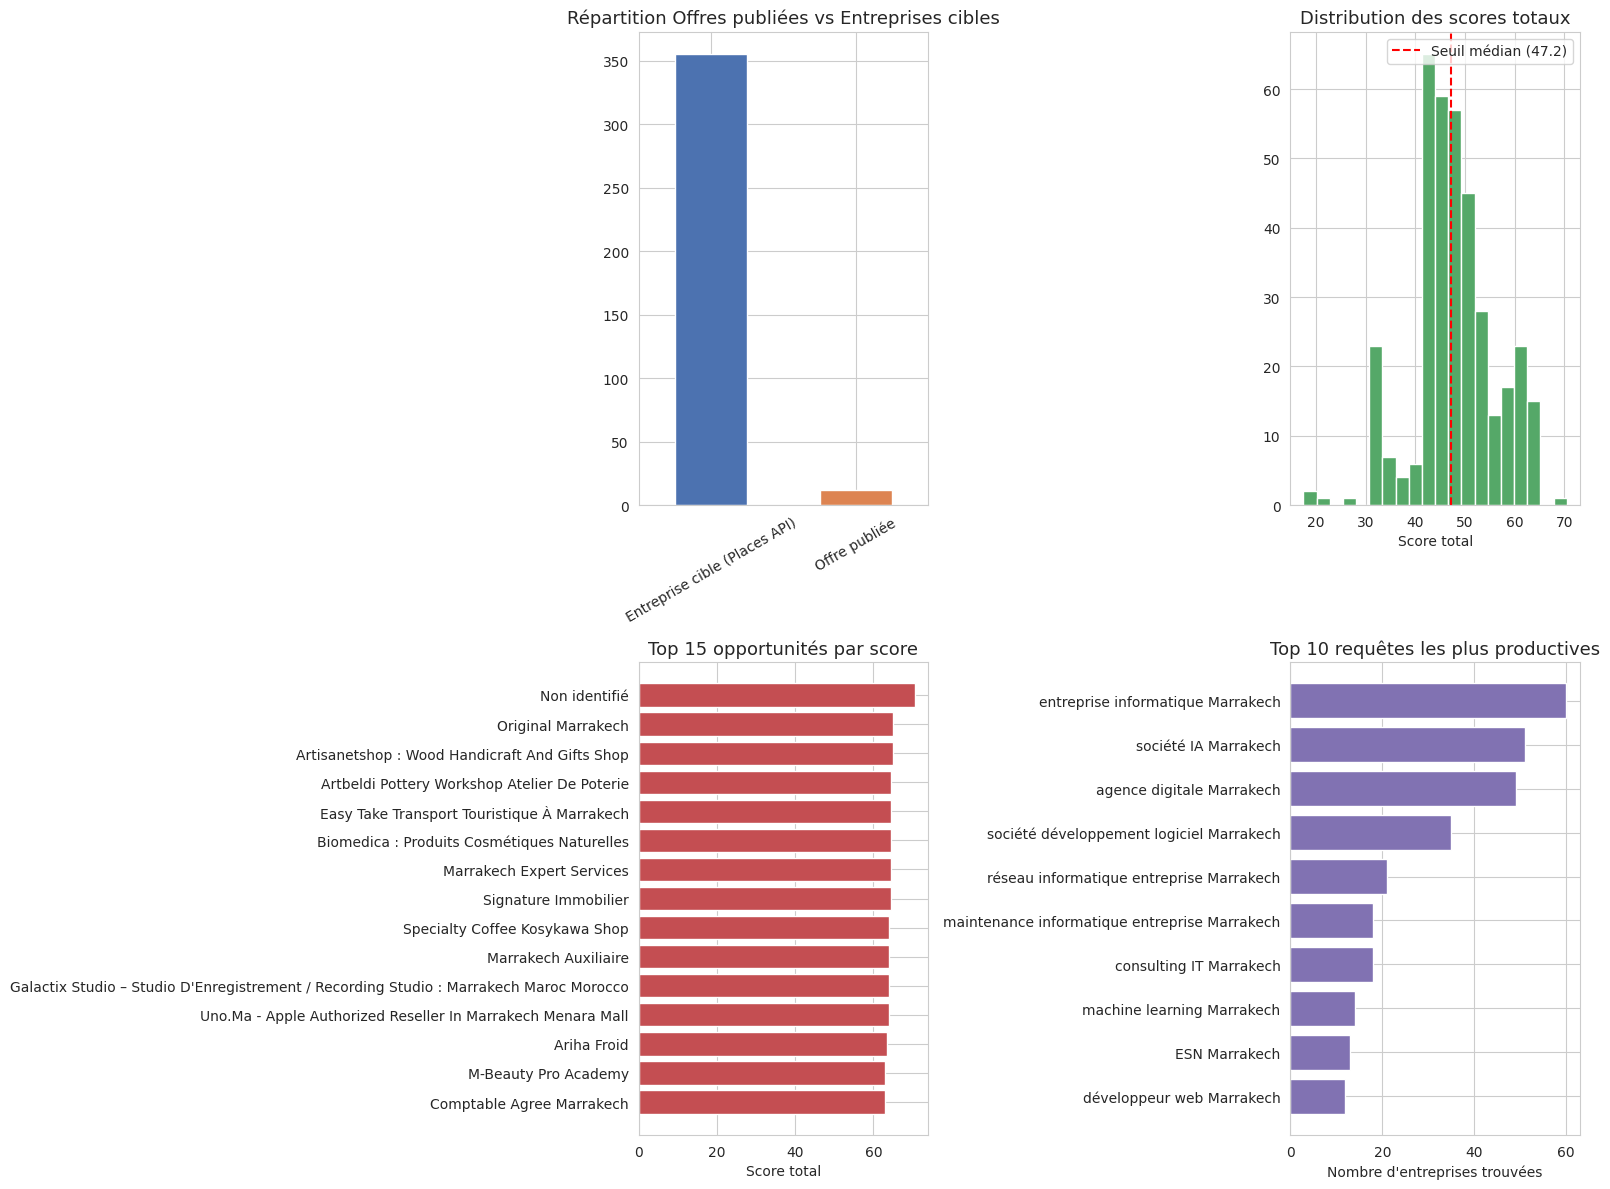

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dashboard sauvegardé ✅


In [ ]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Répartition par type de source
df_score["type_source"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color=["#4C72B0", "#DD8452"]
)
axes[0, 0].set_title("Répartition Offres publiées vs Entreprises cibles", fontsize=13)
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Distribution des scores
axes[0, 1].hist(df_score["score_total"], bins=20, color="#55A868", edgecolor="white")
axes[0, 1].axvline(seuil, color="red", linestyle="--", label=f"Seuil médian ({seuil:.1f})")
axes[0, 1].set_title("Distribution des scores totaux", fontsize=13)
axes[0, 1].set_xlabel("Score total")
axes[0, 1].legend()

# 3. Top 15 entreprises par score
top15 = df_score.head(15)
axes[1, 0].barh(top15["nom_entreprise"], top15["score_total"], color="#C44E52")
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("Top 15 opportunités par score", fontsize=13)
axes[1, 0].set_xlabel("Score total")

# 4. Répartition par requête source (top 10 requêtes les plus fournies)
top_requetes = df_score["requete_source"].value_counts().head(10)
axes[1, 1].barh(top_requetes.index, top_requetes.values, color="#8172B2")
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Top 10 requêtes les plus productives", fontsize=13)
axes[1, 1].set_xlabel("Nombre d'entreprises trouvées")

plt.tight_layout()
plt.savefig("dashboard_opportunites_marrakech.png", dpi=150, bbox_inches="tight")
plt.show()

files.download("dashboard_opportunites_marrakech.png")
print("Dashboard sauvegardé ✅")

In [ ]:
from openpyxl import Workbook
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

df_tracker = df_score.copy()
df_tracker["statut_candidature"] = "À contacter"
df_tracker["date_contact"] = ""
df_tracker["notes_perso"] = ""
df_tracker["priorite"] = df_tracker["score_total"].apply(
    lambda x: "Haute" if x >= df_tracker["score_total"].quantile(0.75)
    else ("Moyenne" if x >= df_tracker["score_total"].quantile(0.4) else "Basse")
)

colonnes_tracker = [
    "nom_entreprise", "titre_poste", "type_source", "adresse",
    "note_entreprise", "nb_avis", "type_contrat", "score_total",
    "priorite", "statut_candidature", "date_contact", "notes_perso", "lien"
]
df_tracker = df_tracker[colonnes_tracker]

wb = Workbook()
ws = wb.active
ws.title = "Tracker Candidatures"

for row in dataframe_to_rows(df_tracker, index=False, header=True):
    ws.append(row)

# Style en-tête
header_fill = PatternFill(start_color="2E4053", end_color="2E4053", fill_type="solid")
header_font = Font(color="FFFFFF", bold=True, size=11)
for cell in ws[1]:
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

# Largeurs de colonnes
largeurs = [30, 35, 22, 35, 12, 10, 15, 12, 12, 18, 15, 30, 40]
for i, largeur in enumerate(largeurs, 1):
    ws.column_dimensions[get_column_letter(i)].width = largeur

ws.freeze_panes = "A2"
nb_lignes = len(df_tracker) + 1

# Liste déroulante : statut_candidature (colonne J)
dv_statut = DataValidation(
    type="list",
    formula1='"À contacter,CV envoyé,En attente réponse,Entretien programmé,Entretien passé,Offre reçue,Refusé,Relancé,Abandonné"',
    allow_blank=True
)
ws.add_data_validation(dv_statut)
dv_statut.add(f"J2:J{nb_lignes}")

# Liste déroulante : priorite (colonne I)
dv_priorite = DataValidation(
    type="list",
    formula1='"Haute,Moyenne,Basse"',
    allow_blank=True
)
ws.add_data_validation(dv_priorite)
dv_priorite.add(f"I2:I{nb_lignes}")

# Mise en forme conditionnelle simple sur le statut (couleurs)
couleurs_statut = {
    "À contacter": "FCE4D6",
    "CV envoyé": "D9E1F2",
    "En attente réponse": "FFF2CC",
    "Entretien programmé": "C6E0B4",
    "Entretien passé": "A9D18E",
    "Offre reçue": "70AD47",
    "Refusé": "F4CCCC",
    "Relancé": "D9D2E9",
    "Abandonné": "D9D9D9"
}
# (La coloration dynamique par valeur nécessite un choix manuel utilisateur ;
# on applique juste la validation, la couleur peut être ajoutée cellule par cellule si besoin)

wb.save("tracker_candidatures_marrakech.xlsx")
files.download("tracker_candidatures_marrakech.xlsx")
print(f"✅ Tracker Excel généré avec {len(df_tracker)} entreprises/offres, listes déroulantes actives sur 'priorite' et 'statut_candidature'")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Tracker Excel généré avec 367 entreprises/offres, listes déroulantes actives sur 'priorite' et 'statut_candidature'


In [ ]:
from openpyxl import load_workbook

# Filtrer les lignes liées à IA/Data
mots_ia_data = ["intelligence artificielle", "ia", "ai", "data", "machine learning", "big data", "analyste"]

def est_ia_data(row):
    texte = f"{row['titre_poste']} {row['requete_source'] if pd.notna(row['requete_source']) else ''}".lower()
    return any(mot in texte for mot in mots_ia_data)

df_ia_data = df_tracker[df_tracker.apply(est_ia_data, axis=1)].copy()
print(f"Entreprises/offres IA & Data identifiées : {len(df_ia_data)} / {len(df_tracker)}")

# Réouvrir le fichier tracker déjà généré et y ajouter l'onglet
wb2 = load_workbook("tracker_candidatures_marrakech.xlsx")
ws2 = wb2.create_sheet("IA & Data uniquement")

for row in dataframe_to_rows(df_ia_data, index=False, header=True):
    ws2.append(row)

# Style en-tête identique
for cell in ws2[1]:
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for i, largeur in enumerate(largeurs, 1):
    ws2.column_dimensions[get_column_letter(i)].width = largeur

ws2.freeze_panes = "A2"
nb_lignes_ia = len(df_ia_data) + 1

# Mêmes listes déroulantes sur ce nouvel onglet
dv_statut2 = DataValidation(
    type="list",
    formula1='"À contacter,CV envoyé,En attente réponse,Entretien programmé,Entretien passé,Offre reçue,Refusé,Relancé,Abandonné"',
    allow_blank=True
)
ws2.add_data_validation(dv_statut2)
dv_statut2.add(f"J2:J{nb_lignes_ia}")

dv_priorite2 = DataValidation(
    type="list",
    formula1='"Haute,Moyenne,Basse"',
    allow_blank=True
)
ws2.add_data_validation(dv_priorite2)
dv_priorite2.add(f"I2:I{nb_lignes_ia}")

wb2.save("tracker_candidatures_marrakech.xlsx")
files.download("tracker_candidatures_marrakech.xlsx")
print(f"✅ Onglet 'IA & Data uniquement' ajouté avec {len(df_ia_data)} lignes, fichier tracker mis à jour et retéléchargé")

KeyError: 'requete_source'

In [ ]:
from openpyxl import load_workbook

# Filtrer les lignes liées à IA/Data (on utilise df_score qui contient requete_source)
mots_ia_data = ["intelligence artificielle", "ia", "ai", "data", "machine learning", "big data", "analyste"]

def est_ia_data(row):
    texte = f"{row['titre_poste']} {row['requete_source'] if pd.notna(row['requete_source']) else ''}".lower()
    return any(mot in texte for mot in mots_ia_data)

df_ia_data_full = df_score[df_score.apply(est_ia_data, axis=1)].copy()

# Appliquer les mêmes colonnes/format que df_tracker
df_ia_data_full["statut_candidature"] = "À contacter"
df_ia_data_full["date_contact"] = ""
df_ia_data_full["notes_perso"] = ""
df_ia_data_full["priorite"] = df_ia_data_full["score_total"].apply(
    lambda x: "Haute" if x >= df_tracker["score_total"].quantile(0.75)
    else ("Moyenne" if x >= df_tracker["score_total"].quantile(0.4) else "Basse")
)

df_ia_data = df_ia_data_full[colonnes_tracker].copy()

print(f"Entreprises/offres IA & Data identifiées : {len(df_ia_data)} / {len(df_tracker)}")

Entreprises/offres IA & Data identifiées : 97 / 367


In [ ]:
import urllib.parse

def generer_lien_recherche_linkedin(nom_entreprise):
    if pd.isna(nom_entreprise) or nom_entreprise == "Non identifié":
        return ""
    requete = f'site:linkedin.com/company "{nom_entreprise}" Marrakech'
    requete_encodee = urllib.parse.quote(requete)
    return f"https://www.google.com/search?q={requete_encodee}"

# Ajout sur le dataset complet
df_tracker["recherche_linkedin"] = df_tracker["nom_entreprise"].apply(generer_lien_recherche_linkedin)

# Ajout sur le dataset IA/Data
df_ia_data["recherche_linkedin"] = df_ia_data["nom_entreprise"].apply(generer_lien_recherche_linkedin)

# Reconstruire le fichier Excel avec cette nouvelle colonne sur les deux onglets
wb3 = Workbook()
ws_all = wb3.active
ws_all.title = "Tracker Candidatures"

colonnes_tracker_v2 = colonnes_tracker + ["recherche_linkedin"]

for row in dataframe_to_rows(df_tracker[colonnes_tracker_v2], index=False, header=True):
    ws_all.append(row)

for cell in ws_all[1]:
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

largeurs_v2 = largeurs + [45]
for i, largeur in enumerate(largeurs_v2, 1):
    ws_all.column_dimensions[get_column_letter(i)].width = largeur

ws_all.freeze_panes = "A2"
nb_lignes_all = len(df_tracker) + 1

dv_statut_all = DataValidation(
    type="list",
    formula1='"À contacter,CV envoyé,En attente réponse,Entretien programmé,Entretien passé,Offre reçue,Refusé,Relancé,Abandonné"',
    allow_blank=True
)
ws_all.add_data_validation(dv_statut_all)
dv_statut_all.add(f"J2:J{nb_lignes_all}")

dv_priorite_all = DataValidation(
    type="list",
    formula1='"Haute,Moyenne,Basse"',
    allow_blank=True
)
ws_all.add_data_validation(dv_priorite_all)
dv_priorite_all.add(f"I2:I{nb_lignes_all}")

# Onglet IA & Data
ws_ia = wb3.create_sheet("IA & Data uniquement")
for row in dataframe_to_rows(df_ia_data[colonnes_tracker_v2], index=False, header=True):
    ws_ia.append(row)

for cell in ws_ia[1]:
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for i, largeur in enumerate(largeurs_v2, 1):
    ws_ia.column_dimensions[get_column_letter(i)].width = largeur

ws_ia.freeze_panes = "A2"
nb_lignes_ia_v2 = len(df_ia_data) + 1

dv_statut_ia = DataValidation(
    type="list",
    formula1='"À contacter,CV envoyé,En attente réponse,Entretien programmé,Entretien passé,Offre reçue,Refusé,Relancé,Abandonné"',
    allow_blank=True
)
ws_ia.add_data_validation(dv_statut_ia)
dv_statut_ia.add(f"J2:J{nb_lignes_ia_v2}")

dv_priorite_ia = DataValidation(
    type="list",
    formula1='"Haute,Moyenne,Basse"',
    allow_blank=True
)
ws_ia.add_data_validation(dv_priorite_ia)
dv_priorite_ia.add(f"I2:I{nb_lignes_ia_v2}")

wb3.save("tracker_candidatures_marrakech.xlsx")
files.download("tracker_candidatures_marrakech.xlsx")
print(f"✅ Colonne 'recherche_linkedin' ajoutée sur les deux onglets. Fichier final : {len(df_tracker)} entreprises (dont {len(df_ia_data)} IA/Data)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Colonne 'recherche_linkedin' ajoutée sur les deux onglets. Fichier final : 367 entreprises (dont 97 IA/Data)


In [ ]:
# ÉTAPE 1 — Setup et chargement des données
!pip install openpyxl -q

import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()  # Upload ton fichier tracker_candidatures_marrakech.xlsx

# Charger le fichier
filename = list(uploaded.keys())[0]
df = pd.read_excel(filename, sheet_name='Tracker Candidatures')

# Exploration rapide
print("Dimensions :", df.shape)
print("\nColonnes :", list(df.columns))
print("\nAperçu :")
display(df.head())

print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

print("\nDoublons (nom_entreprise) :", df.duplicated(subset='nom_entreprise').sum())

print("\nTypes de données :")
print(df.dtypes)

Saving tracker_candidatures_marrakech (1).xlsx to tracker_candidatures_marrakech (1).xlsx
Dimensions : (367, 14)

Colonnes : ['nom_entreprise', 'titre_poste', 'type_source', 'adresse', 'note_entreprise', 'nb_avis', 'type_contrat', 'score_total', 'priorite', 'statut_candidature', 'date_contact', 'notes_perso', 'lien', 'recherche_linkedin']

Aperçu :


,nom_entreprise,titre_poste,type_source,adresse,note_entreprise,nb_avis,type_contrat,score_total,priorite,statut_candidature,date_contact,notes_perso,lien,recherche_linkedin
0,Non identifié,JUNIOR DIGITAL BUSINESS DEVELOPER,Offre publiée,Marrakech,NaN,0,Non précisé,70.5,Haute,À contacter,NaN,NaN,https://ma.trabajo.org/offre-5056-23f8b3a518b4...,NaN
1,Original Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),Rdc - Sous le restaurant la terrasse des épice...,5.0,615,Non précisé,65.0,Haute,À contacter,NaN,NaN,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...
2,Artisanetshop : Wood Handicraft And Gifts Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),"Ensemble Artisanal Marrakech, N° 9 Av. Mohamme...",5.0,342,Non précisé,65.0,Haute,À contacter,NaN,NaN,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...
3,Artbeldi Pottery Workshop Atelier De Poterie,Candidature spontanée / à identifier,Entreprise cible (Places API),N 97 rue Riad Zitoun el Jdid Place jamaâ lfna ...,4.9,334,Non précisé,64.5,Haute,À contacter,NaN,NaN,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...
4,Easy Take Transport Touristique À Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),"3ème étage, elmansour imm alouarda, n 18 Av. Y...",4.9,209,Non précisé,64.5,Haute,À contacter,NaN,NaN,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...



Valeurs manquantes par colonne :
nom_entreprise          0
titre_poste             0
type_source             0
adresse                 0
note_entreprise        40
nb_avis                 0
type_contrat            0
score_total             0
priorite                0
statut_candidature      0
date_contact          367
notes_perso           367
lien                    0
recherche_linkedin     12
dtype: int64

Doublons (nom_entreprise) : 11

Types de données :
nom_entreprise         object
titre_poste            object
type_source            object
adresse                object
note_entreprise       float64
nb_avis                 int64
type_contrat           object
score_total           float64
priorite               object
statut_candidature     object
date_contact          float64
notes_perso           float64
lien                   object
recherche_linkedin     object
dtype: object


In [ ]:
# ÉTAPE 2 — Nettoyage des données

df_clean = df.copy()

# 1. Nettoyer les espaces/caractères invisibles dans le texte
text_cols = ['nom_entreprise', 'titre_poste', 'type_source', 'adresse',
             'type_contrat', 'priorite', 'statut_candidature', 'notes_perso']
for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].replace('None', np.nan)

# 2. Supprimer les doublons exacts (même entreprise + même lien)
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['nom_entreprise', 'lien'], keep='first')
print(f"Doublons supprimés : {before - len(df_clean)}")

# 3. Convertir les colonnes numériques proprement
df_clean['note_entreprise'] = pd.to_numeric(df_clean['note_entreprise'], errors='coerce')
df_clean['nb_avis'] = pd.to_numeric(df_clean['nb_avis'], errors='coerce').fillna(0).astype(int)
df_clean['score_total'] = pd.to_numeric(df_clean['score_total'], errors='coerce')

# 4. Extraire la ville depuis l'adresse (souvent "Marrakech" mais on vérifie)
def extraire_ville(adresse):
    if pd.isna(adresse):
        return "Non précisé"
    if 'marrakech' in str(adresse).lower():
        return "Marrakech"
    return "Autre"

df_clean['ville'] = df_clean['adresse'].apply(extraire_ville)

# 5. Nettoyer titre_poste : uniformiser les candidatures spontanées
df_clean['titre_poste'] = df_clean['titre_poste'].replace(
    'nan', 'Candidature spontanée / à identifier'
)

# 6. Supprimer les lignes sans nom d'entreprise (si il y en a)
df_clean = df_clean.dropna(subset=['nom_entreprise'])
df_clean = df_clean[df_clean['nom_entreprise'] != 'Non identifié']

# 7. Reset index
df_clean = df_clean.reset_index(drop=True)

print(f"\nDimensions après nettoyage : {df_clean.shape}")
print(f"Villes détectées : {df_clean['ville'].value_counts().to_dict()}")
display(df_clean.head())

Doublons supprimés : 0

Dimensions après nettoyage : (355, 15)
Villes détectées : {'Marrakech': 313, 'Autre': 42}


,nom_entreprise,titre_poste,type_source,adresse,note_entreprise,nb_avis,type_contrat,score_total,priorite,statut_candidature,date_contact,notes_perso,lien,recherche_linkedin,ville
0,Original Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),Rdc - Sous le restaurant la terrasse des épice...,5.0,615,Non précisé,65.0,Haute,À contacter,NaN,nan,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...,Marrakech
1,Artisanetshop : Wood Handicraft And Gifts Shop,Candidature spontanée / à identifier,Entreprise cible (Places API),"Ensemble Artisanal Marrakech, N° 9 Av. Mohamme...",5.0,342,Non précisé,65.0,Haute,À contacter,NaN,nan,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...,Marrakech
2,Artbeldi Pottery Workshop Atelier De Poterie,Candidature spontanée / à identifier,Entreprise cible (Places API),N 97 rue Riad Zitoun el Jdid Place jamaâ lfna ...,4.9,334,Non précisé,64.5,Haute,À contacter,NaN,nan,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...,Marrakech
3,Easy Take Transport Touristique À Marrakech,Candidature spontanée / à identifier,Entreprise cible (Places API),"3ème étage, elmansour imm alouarda, n 18 Av. Y...",4.9,209,Non précisé,64.5,Haute,À contacter,NaN,nan,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...,Marrakech
4,Biomedica : Produits Cosmétiques Naturelles,Candidature spontanée / à identifier,Entreprise cible (Places API),"37 Rue Touareg, Marrakech 40000, Maroc",4.9,404,Non précisé,64.5,Haute,À contacter,NaN,nan,https://www.google.com/maps/place/?q=place_id:...,https://www.google.com/search?q=site%3Alinkedi...,Marrakech


In [ ]:
# ÉTAPE 3 — Classification par secteur et domaine

# Dictionnaire de mots-clés -> secteur précis
secteurs_keywords = {
    'Hôtellerie & Riad': ['riad', 'hotel', 'hôtel', 'resort', 'auberge', 'maison d\'hôte', 'guest house'],
    'Restauration & Café': ['restaurant', 'café', 'coffee', 'cuisine', 'traiteur', 'pizzeria', 'snack'],
    'Tourisme & Loisirs': ['tour', 'excursion', 'voyage', 'travel', 'guide touristique', 'transport touristique', 'activité'],
    'Artisanat & Commerce': ['artisanat', 'artisan', 'poterie', 'tapis', 'souk', 'handicraft', 'boutique', 'shop', 'gift'],
    'Cosmétique & Beauté': ['cosmétique', 'beauté', 'spa', 'hammam', 'parfum', 'esthétique', 'salon de coiffure'],
    'Immobilier': ['immobilier', 'immobilière', 'real estate', 'agence immobilière'],
    'Santé & Médical': ['clinique', 'médical', 'pharmacie', 'dentiste', 'santé', 'hôpital', 'cabinet médical'],
    'Transport & Logistique': ['transport', 'taxi', 'location de voiture', 'car rental', 'logistique', 'livraison'],
    'IA, Data & Tech': ['data', 'ia ', 'intelligence artificielle', 'tech', 'digital', 'software', 'developer', 'analyst', 'engineering', 'genai'],
    'Marketing & Communication': ['marketing', 'communication', 'business developer', 'publicité', 'branding'],
    'Finance & Banque': ['banque', 'finance', 'assurance', 'comptabilité', 'audit'],
    'Éducation & Formation': ['école', 'formation', 'éducation', 'institut', 'université'],
    'BTP & Construction': ['btp', 'construction', 'bâtiment', 'travaux', 'architecte'],
    'Mode & Textile': ['mode', 'textile', 'couture', 'vêtement', 'fashion'],
}

# Regroupement des secteurs en grands domaines
domaine_mapping = {
    'Hôtellerie & Riad': 'Tourisme & Hôtellerie',
    'Restauration & Café': 'Tourisme & Hôtellerie',
    'Tourisme & Loisirs': 'Tourisme & Hôtellerie',
    'Artisanat & Commerce': 'Commerce & Artisanat',
    'Cosmétique & Beauté': 'Bien-être & Cosmétique',
    'Immobilier': 'Immobilier & BTP',
    'BTP & Construction': 'Immobilier & BTP',
    'Santé & Médical': 'Santé',
    'Transport & Logistique': 'Transport & Logistique',
    'IA, Data & Tech': 'Tech & Digital',
    'Marketing & Communication': 'Tech & Digital',
    'Finance & Banque': 'Finance',
    'Éducation & Formation': 'Éducation',
    'Mode & Textile': 'Commerce & Artisanat',
    'Autre / Non classé': 'Autre',
}

def detecter_secteur(row):
    texte = f"{row['nom_entreprise']} {row['titre_poste']}".lower()
    for secteur, mots in secteurs_keywords.items():
        if any(mot in texte for mot in mots):
            return secteur
    return 'Autre / Non classé'

df_clean['secteur'] = df_clean.apply(detecter_secteur, axis=1)
df_clean['domaine'] = df_clean['secteur'].map(domaine_mapping)

print("Répartition par secteur :")
print(df_clean['secteur'].value_counts())
print("\nRépartition par domaine :")
print(df_clean['domaine'].value_counts())

display(df_clean[['nom_entreprise', 'titre_poste', 'secteur', 'domaine']].head(15))

Répartition par secteur :
secteur
Autre / Non classé           220
IA, Data & Tech               91
Marketing & Communication     21
Cosmétique & Beauté            5
Éducation & Formation          5
Immobilier                     3
Tourisme & Loisirs             2
Artisanat & Commerce           2
Restauration & Café            2
Finance & Banque               2
Transport & Logistique         1
BTP & Construction             1
Name: count, dtype: int64

Répartition par domaine :
domaine
Autre                     220
Tech & Digital            112
Bien-être & Cosmétique      5
Éducation                   5
Tourisme & Hôtellerie       4
Immobilier & BTP            4
Commerce & Artisanat        2
Finance                     2
Transport & Logistique      1
Name: count, dtype: int64


,nom_entreprise,titre_poste,secteur,domaine
0,Original Marrakech,Candidature spontanée / à identifier,Autre / Non classé,Autre
1,Artisanetshop : Wood Handicraft And Gifts Shop,Candidature spontanée / à identifier,Artisanat & Commerce,Commerce & Artisanat
2,Artbeldi Pottery Workshop Atelier De Poterie,Candidature spontanée / à identifier,Artisanat & Commerce,Commerce & Artisanat
3,Easy Take Transport Touristique À Marrakech,Candidature spontanée / à identifier,Tourisme & Loisirs,Tourisme & Hôtellerie
4,Biomedica : Produits Cosmétiques Naturelles,Candidature spontanée / à identifier,Cosmétique & Beauté,Bien-être & Cosmétique
5,Marrakech Expert Services,Candidature spontanée / à identifier,Autre / Non classé,Autre
6,Signature Immobilier,Candidature spontanée / à identifier,Immobilier,Immobilier & BTP
7,Specialty Coffee Kosykawa Shop,Candidature spontanée / à identifier,Restauration & Café,Tourisme & Hôtellerie
8,Marrakech Auxiliaire,Candidature spontanée / à identifier,Autre / Non classé,Autre
9,Galactix Studio – Studio D'Enregistrement / Re...,Candidature spontanée / à identifier,Autre / Non classé,Autre


In [ ]:
# ÉTAPE 3bis (a) — Inspecter les noms non classés
autres = df_clean[df_clean['secteur'] == 'Autre / Non classé']
print(f"{len(autres)} entreprises non classées\n")
for nom in autres['nom_entreprise'].head(50):
    print(nom)

220 entreprises non classées

Original Marrakech
Marrakech Expert Services
Marrakech Auxiliaire
Galactix Studio – Studio D'Enregistrement / Recording Studio : Marrakech Maroc Morocco
Uno.Ma - Apple Authorized Reseller In Marrakech Menara Mall
Ariha Froid
M-Beauty Pro Academy
Comptable Agree Marrakech
Ballooning Marrakech
Km Beauty Academy Le Distributeur Officiel De La Marque Ekseption Au Maroc.
8Sky Production Marrakech
Expert Groupe Maroc (Panneaux Solaires Marrakech. Climatiseur Marrakech)
Les Maîtres D'Hygiène Marrakech Désinsectisation, Dératisation A Marrakech 3D
Electricien Marrakech
Conciergerie Marrakech By Valérie
Complexe Urbain 5
Gymaholic Club
Axigeo Ouail Benkirane Géomètres Topographes
Les Sens De Marrakech Médina Dar El Bacha
Emballage Mazirh Marrakech
Dxn Marrakech Official
Allianz Solar Marrakech
Flow Reformer Pilates
Chifaa Conseil : Domiciliation D'Entreprise A Marrakech
Experts Hygiene Marrakech
Image Green - Société De Jardinage À Marrakech
Hosteen Domiciliation M

In [ ]:
# ÉTAPE 3bis (b) — Dictionnaire élargi

secteurs_keywords = {
    'Hôtellerie & Riad': ['riad', 'hotel', 'hôtel', 'resort', 'auberge', "maison d'hôte", 'guest house', 'dar '],
    'Restauration & Café': ['restaurant', 'café', 'coffee', 'cuisine', 'traiteur', 'pizzeria', 'snack', 'pâtisserie', 'boulangerie', 'glacier'],
    'Tourisme & Loisirs': ['tour', 'excursion', 'voyage', 'travel', 'guide touristique', 'transport touristique', 'activité', 'agence de voyage', 'trekking', 'désert', 'quad', 'balloon'],
    'Artisanat & Commerce': ['artisanat', 'artisan', 'poterie', 'tapis', 'souk', 'handicraft', 'boutique', 'shop', 'gift', 'bazar', 'antiquité', 'galerie', 'décoration', 'librairie', 'papeterie'],
    'Cosmétique & Beauté': ['cosmétique', 'beauté', 'spa', 'hammam', 'parfum', 'esthétique', 'salon de coiffure', 'institut de beauté', 'coiffure', 'onglerie'],
    'Immobilier': ['immobilier', 'immobilière', 'real estate', 'agence immobilière', 'promotion immobilière'],
    'Santé & Médical': ['clinique', 'médical', 'pharmacie', 'dentiste', 'santé', 'hôpital', 'cabinet médical', 'kinésithérapie', 'laboratoire', 'radiologie', 'ophtalmo'],
    'Transport & Logistique': ['transport', 'taxi', 'location de voiture', 'car rental', 'logistique', 'livraison', 'déménagement', 'fret'],
    'IA, Data & Tech': ['data', 'ia ', 'intelligence artificielle', 'tech', 'digital', 'software', 'developer', 'analyst', 'engineering', 'genai', 'informatique', 'télécom', 'web', 'startup'],
    'Marketing & Communication': ['marketing', 'communication', 'business developer', 'publicité', 'branding', 'événementiel', 'event', 'wedding', 'photographe', 'studio photo'],
    'Finance & Banque': ['banque', 'finance', 'assurance', 'comptabilité', 'audit', 'cabinet comptable', 'expert-comptable', 'crédit'],
    'Éducation & Formation': ['école', 'formation', 'éducation', 'institut', 'université', 'crèche', 'garderie', 'académie', 'cours', 'auto-école'],
    'BTP & Construction': ['btp', 'construction', 'bâtiment', 'travaux', 'architecte', 'matériaux', 'plomberie', 'électricité générale'],
    'Mode & Textile': ['mode', 'textile', 'couture', 'vêtement', 'fashion', 'prêt-à-porter', 'tailleur', 'bijouterie', 'joaillerie', 'optique', 'opticien'],
    'Services Juridiques': ['avocat', 'notaire', 'cabinet juridique', 'huissier'],
    'Sport & Bien-être': ['sport', 'fitness', 'gym', 'yoga', 'piscine', 'golf', 'club'],
    'Automobile': ['garage', 'auto ', 'automobile', 'pneu', 'carrosserie', 'concession'],
    'Services Divers': ['pressing', 'laverie', 'nettoyage', 'sécurité', 'gardiennage', 'consulting', 'conseil'],
}

df_clean['secteur'] = df_clean.apply(detecter_secteur, axis=1)
df_clean['domaine'] = df_clean['secteur'].map(domaine_mapping).fillna('Autre')

print("Répartition par secteur :")
print(df_clean['secteur'].value_counts())
print(f"\nToujours non classées : {(df_clean['secteur']=='Autre / Non classé').sum()} / {len(df_clean)}")

Répartition par secteur :
secteur
IA, Data & Tech              151
Autre / Non classé           147
Services Divers               14
Marketing & Communication     13
Cosmétique & Beauté            5
Finance & Banque               4
Éducation & Formation          4
Tourisme & Loisirs             3
Immobilier                     3
Restauration & Café            2
Artisanat & Commerce           2
Transport & Logistique         2
Hôtellerie & Riad              1
Sport & Bien-être              1
Services Juridiques            1
BTP & Construction             1
Santé & Médical                1
Name: count, dtype: int64

Toujours non classées : 147 / 355


In [ ]:
# ÉTAPE 4 — Diviser la data par secteur et par domaine

import os

# Créer des dossiers de sortie
os.makedirs('export/par_secteur', exist_ok=True)
os.makedirs('export/par_domaine', exist_ok=True)

# --- Colonnes utiles à garder dans les exports ---
cols_export = ['nom_entreprise', 'secteur', 'domaine', 'titre_poste', 'type_source',
               'adresse', 'ville', 'note_entreprise', 'nb_avis', 'type_contrat',
               'score_total', 'priorite', 'statut_candidature', 'date_contact',
               'notes_perso', 'lien', 'recherche_linkedin']

# 1. Un CSV par secteur
for secteur in df_clean['secteur'].unique():
    sous_df = df_clean[df_clean['secteur'] == secteur][cols_export]
    nom_fichier = secteur.replace('/', '-').replace(' ', '_').replace(',', '')
    sous_df.to_csv(f'export/par_secteur/{nom_fichier}.csv', index=False)

# 2. Un CSV par domaine
for domaine in df_clean['domaine'].unique():
    sous_df = df_clean[df_clean['domaine'] == domaine][cols_export]
    nom_fichier = domaine.replace('/', '-').replace(' ', '_').replace('&', 'et')
    sous_df.to_csv(f'export/par_domaine/{nom_fichier}.csv', index=False)

# 3. Un fichier Excel unique avec une feuille par secteur (pratique pour partage)
with pd.ExcelWriter('export/tracker_par_secteur.xlsx', engine='openpyxl') as writer:
    df_clean[cols_export].to_excel(writer, sheet_name='Toutes_donnees', index=False)
    for secteur in df_clean['secteur'].unique():
        sous_df = df_clean[df_clean['secteur'] == secteur][cols_export]
        nom_feuille = secteur[:31].replace('/', '-')  # Excel limite les noms de feuille à 31 caractères
        sous_df.to_excel(writer, sheet_name=nom_feuille, index=False)

# 4. Un fichier Excel unique avec une feuille par domaine
with pd.ExcelWriter('export/tracker_par_domaine.xlsx', engine='openpyxl') as writer:
    df_clean[cols_export].to_excel(writer, sheet_name='Toutes_donnees', index=False)
    for domaine in df_clean['domaine'].unique():
        sous_df = df_clean[df_clean['domaine'] == domaine][cols_export]
        nom_feuille = domaine[:31].replace('/', '-')
        sous_df.to_excel(writer, sheet_name=nom_feuille, index=False)

print("Export terminé !")
print("- Fichiers CSV individuels dans export/par_secteur/ et export/par_domaine/")
print("- 2 fichiers Excel : tracker_par_secteur.xlsx et tracker_par_domaine.xlsx")

# Télécharger les 2 fichiers Excel principaux
files.download('export/tracker_par_secteur.xlsx')
files.download('export/tracker_par_domaine.xlsx')

Export terminé !
- Fichiers CSV individuels dans export/par_secteur/ et export/par_domaine/
- 2 fichiers Excel : tracker_par_secteur.xlsx et tracker_par_domaine.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_1788/997041410.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y='secteur', order=ordre, palette='viridis')


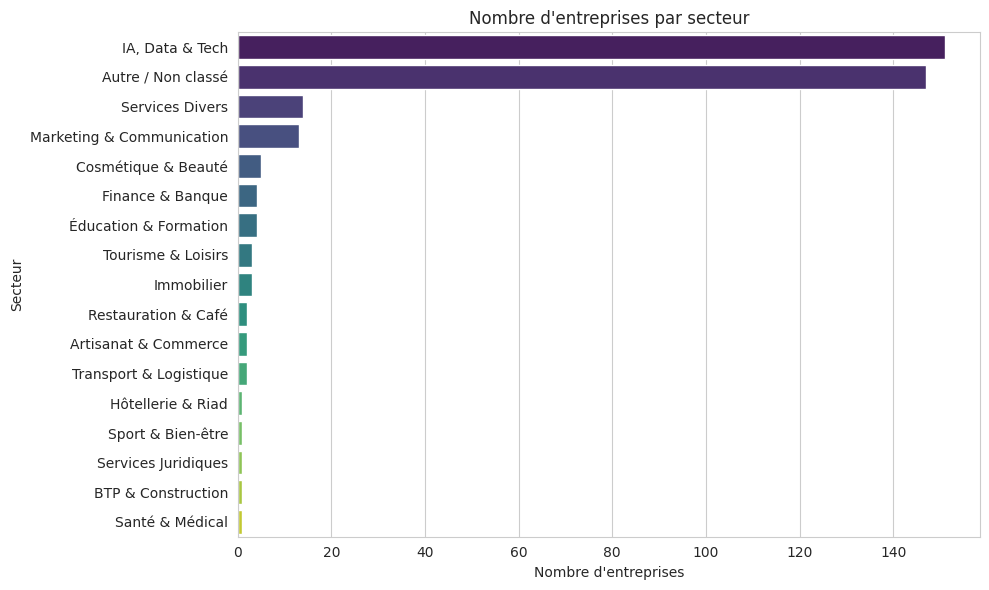

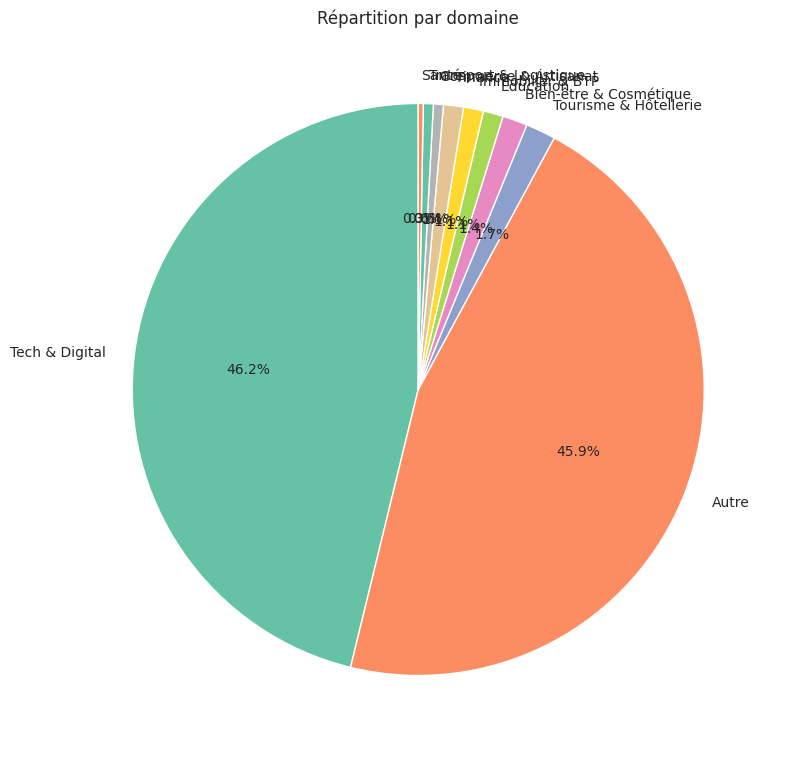

/tmp/ipykernel_1788/997041410.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=score_par_secteur.values, y=score_par_secteur.index, palette='mako')


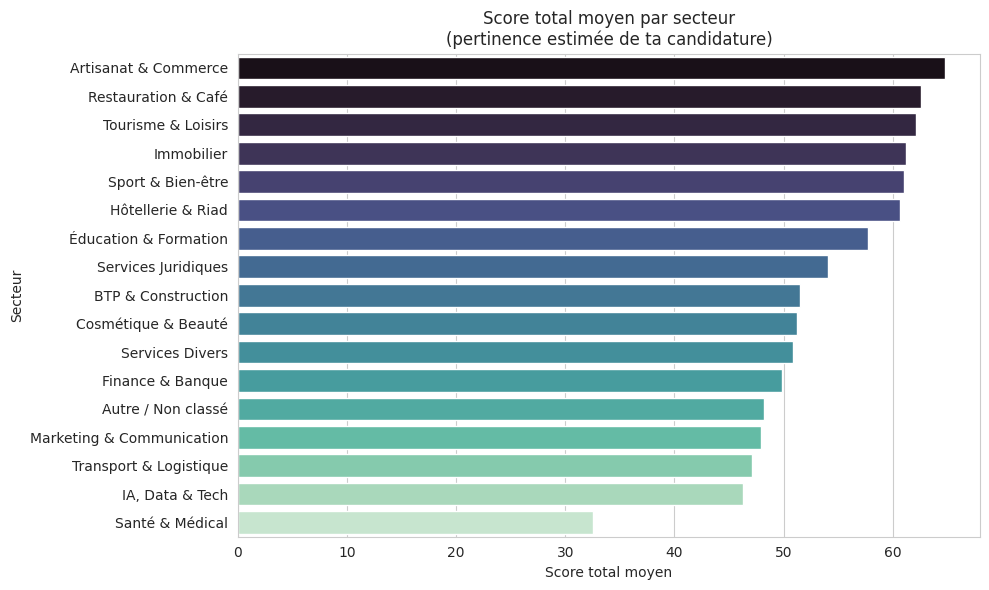

Score moyen par secteur :
secteur
Artisanat & Commerce         64.750000
Restauration & Café          62.600000
Tourisme & Loisirs           62.166667
Immobilier                   61.233333
Sport & Bien-être            61.000000
Hôtellerie & Riad            60.700000
Éducation & Formation        57.750000
Services Juridiques          54.100000
BTP & Construction           51.500000
Cosmétique & Beauté          51.260000
Services Divers              50.821429
Finance & Banque             49.850000
Autre / Non classé           48.197279
Marketing & Communication    47.930769
Transport & Logistique       47.100000
IA, Data & Tech              46.315894
Santé & Médical              32.500000
Name: score_total, dtype: float64


<Figure size 1200x600 with 0 Axes>

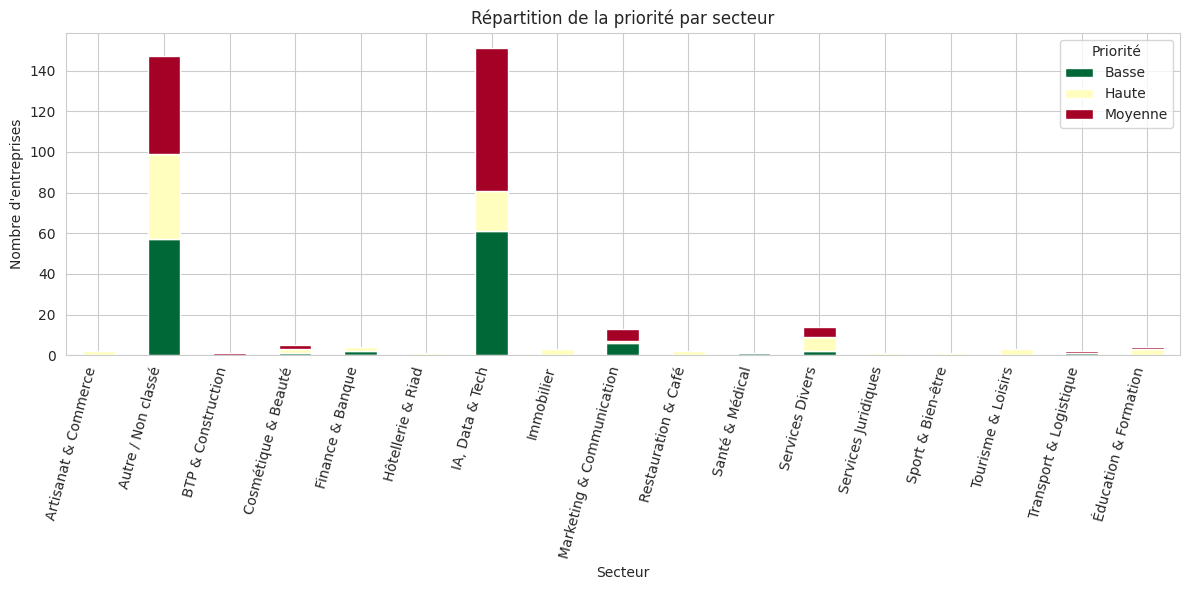

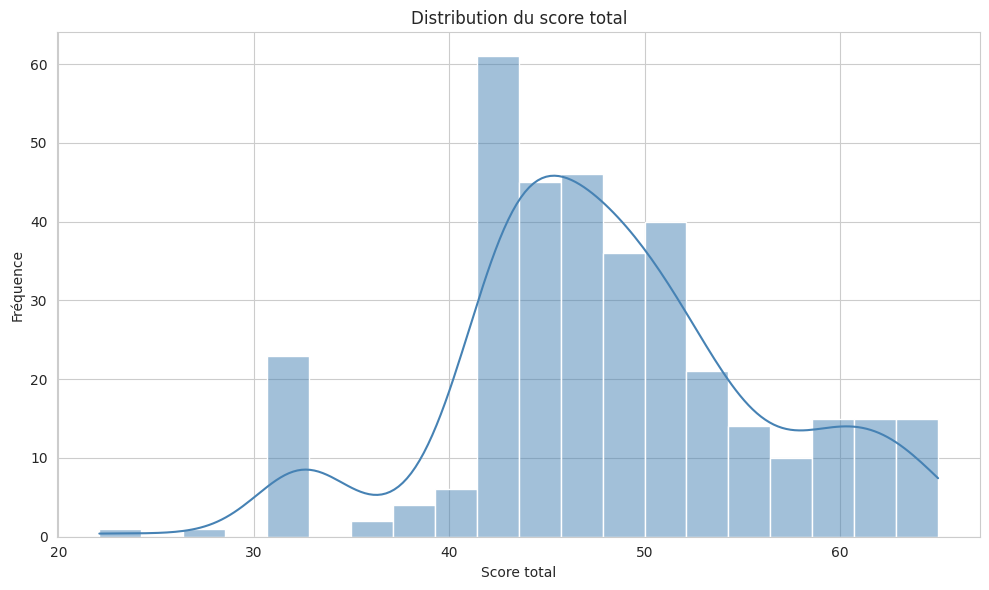

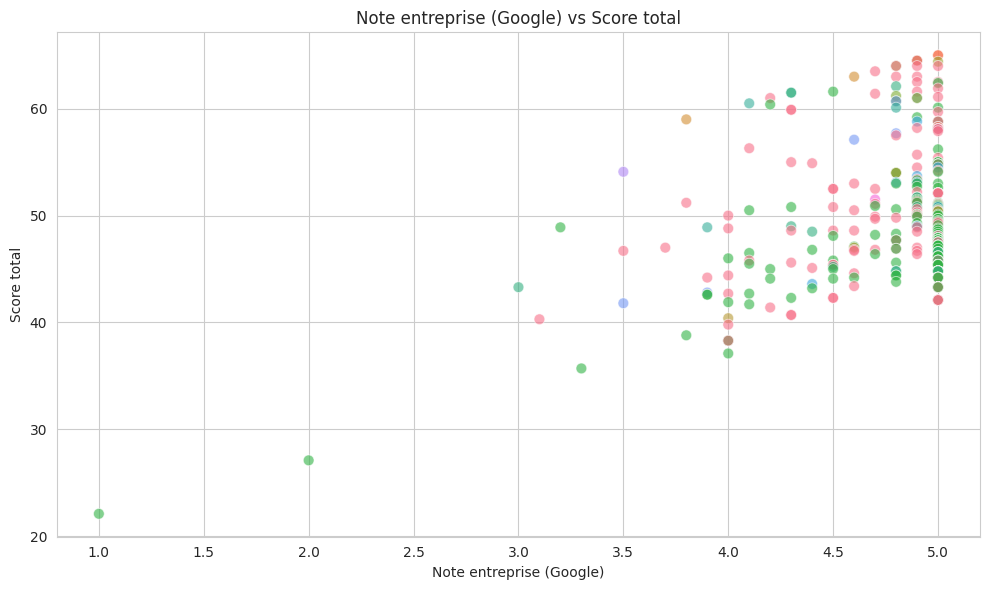

/tmp/ipykernel_1788/997041410.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='score_total', y='nom_entreprise', palette='flare')


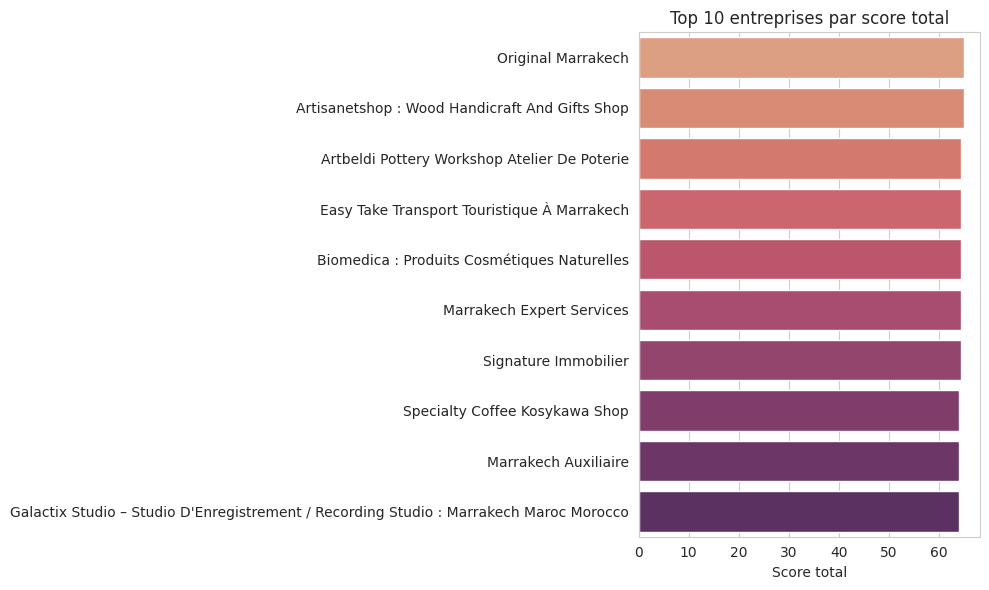


Top 10 entreprises prioritaires :


,nom_entreprise,score_total,secteur
0,Original Marrakech,65.0,Autre / Non classé
1,Artisanetshop : Wood Handicraft And Gifts Shop,65.0,Artisanat & Commerce
2,Artbeldi Pottery Workshop Atelier De Poterie,64.5,Artisanat & Commerce
3,Easy Take Transport Touristique À Marrakech,64.5,Tourisme & Loisirs
4,Biomedica : Produits Cosmétiques Naturelles,64.5,Cosmétique & Beauté
5,Marrakech Expert Services,64.5,Autre / Non classé
6,Signature Immobilier,64.4,Immobilier
7,Specialty Coffee Kosykawa Shop,64.0,Restauration & Café
8,Marrakech Auxiliaire,64.0,Autre / Non classé
9,Galactix Studio – Studio D'Enregistrement / Re...,64.0,Autre / Non classé



RÉSUMÉ DE L'ANALYSE
Total entreprises analysées : 355
Nombre de secteurs identifiés : 17
Score total moyen global : 48.11
Secteur le plus représenté : IA, Data & Tech
Secteur avec le meilleur score moyen : Artisanat & Commerce (64.75)
Entreprises priorité 'Haute' : 90


In [ ]:
# ÉTAPE 5 — Visualisation et analyse

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# ============================================
# 1. Répartition des entreprises par secteur
# ============================================
plt.figure(figsize=(10, 6))
ordre = df_clean['secteur'].value_counts().index
sns.countplot(data=df_clean, y='secteur', order=ordre, palette='viridis')
plt.title('Nombre d\'entreprises par secteur')
plt.xlabel('Nombre d\'entreprises')
plt.ylabel('Secteur')
plt.tight_layout()
plt.savefig('export/1_repartition_secteur.png', dpi=150)
plt.show()

# ============================================
# 2. Répartition par grand domaine
# ============================================
plt.figure(figsize=(8, 8))
df_clean['domaine'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
plt.title('Répartition par domaine')
plt.ylabel('')
plt.tight_layout()
plt.savefig('export/2_repartition_domaine.png', dpi=150)
plt.show()

# ============================================
# 3. Score total moyen PAR SECTEUR (répond à ta question)
# ============================================
plt.figure(figsize=(10, 6))
score_par_secteur = df_clean.groupby('secteur')['score_total'].mean().sort_values(ascending=False)
sns.barplot(x=score_par_secteur.values, y=score_par_secteur.index, palette='mako')
plt.title('Score total moyen par secteur\n(pertinence estimée de ta candidature)')
plt.xlabel('Score total moyen')
plt.ylabel('Secteur')
plt.tight_layout()
plt.savefig('export/3_score_moyen_par_secteur.png', dpi=150)
plt.show()

print("Score moyen par secteur :")
print(score_par_secteur)

# ============================================
# 4. Priorité par secteur (croisement)
# ============================================
plt.figure(figsize=(12, 6))
priorite_secteur = pd.crosstab(df_clean['secteur'], df_clean['priorite'])
priorite_secteur.plot(kind='bar', stacked=True, colormap='RdYlGn_r', figsize=(12, 6))
plt.title('Répartition de la priorité par secteur')
plt.xlabel('Secteur')
plt.ylabel('Nombre d\'entreprises')
plt.xticks(rotation=75, ha='right')
plt.legend(title='Priorité')
plt.tight_layout()
plt.savefig('export/4_priorite_par_secteur.png', dpi=150)
plt.show()

# ============================================
# 5. Distribution du score total (toutes entreprises)
# ============================================
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['score_total'], bins=20, kde=True, color='steelblue')
plt.title('Distribution du score total')
plt.xlabel('Score total')
plt.ylabel('Fréquence')
plt.tight_layout()
plt.savefig('export/5_distribution_score.png', dpi=150)
plt.show()

# ============================================
# 6. Note Google (note_entreprise) vs score_total
# ============================================
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='note_entreprise', y='score_total', hue='secteur',
                 legend=False, alpha=0.6, s=60)
plt.title('Note entreprise (Google) vs Score total')
plt.xlabel('Note entreprise (Google)')
plt.ylabel('Score total')
plt.tight_layout()
plt.savefig('export/6_note_vs_score.png', dpi=150)
plt.show()

# ============================================
# 7. Top 10 des entreprises avec le meilleur score
# ============================================
plt.figure(figsize=(10, 6))
top10 = df_clean.nlargest(10, 'score_total')[['nom_entreprise', 'score_total', 'secteur']]
sns.barplot(data=top10, x='score_total', y='nom_entreprise', palette='flare')
plt.title('Top 10 entreprises par score total')
plt.xlabel('Score total')
plt.ylabel('')
plt.tight_layout()
plt.savefig('export/7_top10_entreprises.png', dpi=150)
plt.show()

print("\nTop 10 entreprises prioritaires :")
display(top10)

# ============================================
# 8. Résumé statistique final
# ============================================
print("\n" + "="*50)
print("RÉSUMÉ DE L'ANALYSE")
print("="*50)
print(f"Total entreprises analysées : {len(df_clean)}")
print(f"Nombre de secteurs identifiés : {df_clean['secteur'].nunique()}")
print(f"Score total moyen global : {df_clean['score_total'].mean():.2f}")
print(f"Secteur le plus représenté : {df_clean['secteur'].value_counts().idxmax()}")
print(f"Secteur avec le meilleur score moyen : {score_par_secteur.idxmax()} ({score_par_secteur.max():.2f})")
print(f"Entreprises priorité 'Haute' : {(df_clean['priorite']=='Haute').sum()}")

Secteurs avec échantillon fiable (≥10 entreprises) :
secteur
IA, Data & Tech              151
Autre / Non classé           147
Services Divers               14
Marketing & Communication     13
Name: count, dtype: int64

Secteurs exclus (échantillon trop petit, non fiable) :
secteur
Cosmétique & Beauté       5
Finance & Banque          4
Éducation & Formation     4
Tourisme & Loisirs        3
Immobilier                3
Restauration & Café       2
Artisanat & Commerce      2
Transport & Logistique    2
Hôtellerie & Riad         1
Sport & Bien-être         1
Services Juridiques       1
BTP & Construction        1
Santé & Médical           1
Name: count, dtype: int64


/tmp/ipykernel_1788/570695993.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=score_fiable['mean'], y=score_fiable.index, palette='mako')


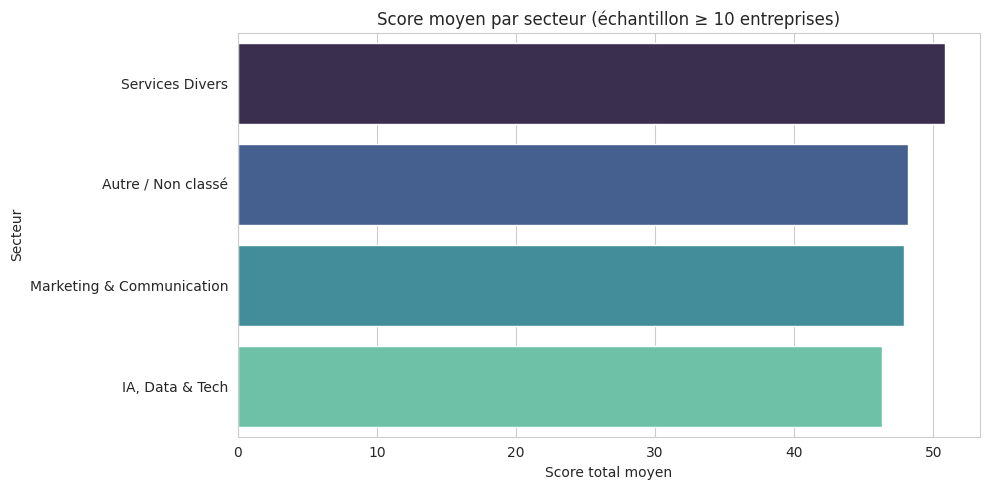


Score moyen (secteurs fiables) :
                                mean  count
secteur                                    
Services Divers            50.821429     14
Autre / Non classé         48.197279    147
Marketing & Communication  47.930769     13
IA, Data & Tech            46.315894    151

Postes liés à l'IT trouvés HORS du secteur 'IA, Data & Tech' :
Aucun — les postes tech sont concentrés uniquement dans le secteur IA/Tech

RÉSUMÉ FIABLE (échantillon ≥ 10)
Secteurs retenus : ['IA, Data & Tech', 'Autre / Non classé', 'Services Divers', 'Marketing & Communication']
Nombre total d'entreprises couvertes : 325 / 355
Secteur avec le meilleur score moyen (fiable) : Services Divers (50.82)


In [ ]:
# ÉTAPE 5bis — Analyse fiable : secteurs avec échantillon suffisant

SEUIL_MIN = 10  # on ignore les secteurs avec moins de 10 entreprises

# Compter les entreprises par secteur
comptage = df_clean['secteur'].value_counts()
secteurs_fiables = comptage[comptage >= SEUIL_MIN].index.tolist()

print(f"Secteurs avec échantillon fiable (≥{SEUIL_MIN} entreprises) :")
print(comptage[comptage >= SEUIL_MIN])
print(f"\nSecteurs exclus (échantillon trop petit, non fiable) :")
print(comptage[comptage < SEUIL_MIN])

# Filtrer la base sur ces secteurs uniquement
df_fiable = df_clean[df_clean['secteur'].isin(secteurs_fiables)].copy()

# ============================================
# Score moyen — version fiable uniquement
# ============================================
plt.figure(figsize=(10, 5))
score_fiable = df_fiable.groupby('secteur')['score_total'].agg(['mean', 'count']).sort_values('mean', ascending=False)
sns.barplot(x=score_fiable['mean'], y=score_fiable.index, palette='mako')
plt.title(f'Score moyen par secteur (échantillon ≥ {SEUIL_MIN} entreprises)')
plt.xlabel('Score total moyen')
plt.ylabel('Secteur')
plt.tight_layout()
plt.savefig('export/8_score_fiable_par_secteur.png', dpi=150)
plt.show()

print("\nScore moyen (secteurs fiables) :")
print(score_fiable)

# ============================================
# Transversalité de l'IT : mots-clés tech dans TOUS les secteurs
# ============================================
mots_tech = ['digital', 'data', 'analyst', 'it ', 'informatique', 'tech',
             'software', 'developer', 'system', 'crm', 'web', 'e-commerce', 'genai', 'ia ']

def contient_mot_tech(titre):
    titre = str(titre).lower()
    return any(mot in titre for mot in mots_tech)

df_clean['lien_tech'] = df_clean['titre_poste'].apply(contient_mot_tech)

# Répartition : combien de postes "tech" existent même hors du secteur IA/Tech ?
transversalite = df_clean[df_clean['secteur'] != 'IA, Data & Tech'].groupby('secteur')['lien_tech'].sum()
transversalite = transversalite[transversalite > 0].sort_values(ascending=False)

print("\nPostes liés à l'IT trouvés HORS du secteur 'IA, Data & Tech' :")
print(transversalite if len(transversalite) > 0 else "Aucun — les postes tech sont concentrés uniquement dans le secteur IA/Tech")

# ============================================
# Résumé final fiable
# ============================================
print("\n" + "="*50)
print("RÉSUMÉ FIABLE (échantillon ≥ 10)")
print("="*50)
print(f"Secteurs retenus : {secteurs_fiables}")
print(f"Nombre total d'entreprises couvertes : {len(df_fiable)} / {len(df_clean)}")
print(f"Secteur avec le meilleur score moyen (fiable) : {score_fiable.index[0]} ({score_fiable['mean'].iloc[0]:.2f})")